<a href="https://colab.research.google.com/github/imanand002/Applied-ML-Lab/blob/main/ML_Exp2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Experiment 2: Iris Flower Classification: Use the Iris dataset to build a classification model that predicts the species of iris flowers

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
import torch.nn as nn
import torch
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler


In [ ]:
df = pd.read_csv('/content/Iris.csv')

In [ ]:
print("Shape:", df.shape)
print("Top 5 rows of the DataFrame:")
print(df.head())
print("Description:")
print(df.describe())
print("Info:")
df.info()

Shape: (150, 6)
Top 5 rows of the DataFrame:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
Description:
               Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
count  150.000000     150.000000    150.000000     150.000000    150.000000
mean    75.500000       5.843333      3.054000       3.758667      1.198667
std     43.445368       0.828066      0.433594       1.764420      0.763161
min      1.000000       4.300000      2.000000       1.000000      0.100000
25%     38.250000       5.100000      2.800000       1.600000      0.300000
50%     75.500000       

In [ ]:
# Use features from the loaded CSV data
X = df[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']].values

# Convert species names to numerical labels and store original target names
iris_target_names = df['Species'].astype('category').cat.categories.values
y = df['Species'].astype('category').cat.codes.values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Shape of X_train:", X_train.shape)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert to tensors
X_train = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
X_test = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.long)

Shape of X_train: (120, 4)


In [ ]:
class IrisNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )

    def forward(self, x):
        return self.net(x)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = IrisNet().to(device) # Re-initialize the model
X_train, y_train = X_train.to(device), y_train.to(device)
# X_val, y_val = X_val.to(device), y_val.to(device) # Move validation data to device (removed during revert)
X_test, y_test = X_test.to(device), y_test.to(device)
print("Model and data moved to device and re-initialized.")

Model and data moved to device and re-initialized.


In [ ]:
criterion = nn.CrossEntropyLoss()  # combines softmax + NLL loss
optimizer = optim.Adam(model.parameters(), lr=0.01) # Re-initialize optimizer for the new model
print("Criterion and Optimizer re-initialized.")

Criterion and Optimizer re-initialized.


In [ ]:
num_epochs = 100
train_losses = []
train_accuracies = []

# Get initial parameter state for debugging
initial_param_state = {name: p.clone().detach() for name, p in model.named_parameters()}

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()

    outputs = model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()

    # Debugging: Check gradients for the first layer (weights) at epoch 0
    if epoch == 0:
        print(f"--- Epoch {epoch} Debug ---")
        print(f"Initial weights of layer0.weight (mean): {model.net[0].weight.data.mean():.6f}")
        if model.net[0].weight.grad is not None:
            print(f"Gradient of layer0.weight (mean before step): {model.net[0].weight.grad.mean():.6f}")
            print(f"Gradient of layer0.weight (max before step): {model.net[0].weight.grad.abs().max():.6f}")
        else:
            print("Gradients are None for layer0.weight.")

    optimizer.step()

    # Debugging: Check if parameters actually changed after step at epoch 0
    if epoch == 0:
        print(f"Weights of layer0.weight (mean after step): {model.net[0].weight.data.mean():.6f}")
        print(f"--- End Epoch {epoch} Debug ---\n")


    train_losses.append(loss.item())

    model.eval()
    with torch.no_grad():
        _, predicted = torch.max(outputs, 1)
        accuracy = (predicted == y_train).sum().item() / y_train.size(0)
        train_accuracies.append(accuracy)

    if (epoch + 1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}, Accuracy: {accuracy:.4f}')

# Final check of parameters after training
final_param_state = {name: p.clone().detach() for name, p in model.named_parameters()}
print("\n--- Final Parameter Change Check ---")
params_changed = False
for name, initial_p in initial_param_state.items():
    if not torch.equal(initial_p, final_param_state[name]):
        print(f"Parameter '{name}' HAS changed.")
        params_changed = True
    else:
        print(f"Parameter '{name}' HAS NOT changed.")
if not params_changed:
    print("WARNING: No model parameters changed during training.")
print("------------------------------------")

--- Epoch 0 Debug ---
Initial weights of layer0.weight (mean): 0.009987
Gradient of layer0.weight (mean before step): 0.000397
Gradient of layer0.weight (max before step): 0.010599
Weights of layer0.weight (mean after step): 0.009680
--- End Epoch 0 Debug ---

Epoch [10/100], Loss: 0.0735, Accuracy: 0.9750
Epoch [20/100], Loss: 0.0670, Accuracy: 0.9750
Epoch [30/100], Loss: 0.0621, Accuracy: 0.9750
Epoch [40/100], Loss: 0.0583, Accuracy: 0.9833
Epoch [50/100], Loss: 0.0552, Accuracy: 0.9833
Epoch [60/100], Loss: 0.0527, Accuracy: 0.9833
Epoch [70/100], Loss: 0.0507, Accuracy: 0.9833
Epoch [80/100], Loss: 0.0489, Accuracy: 0.9833
Epoch [90/100], Loss: 0.0474, Accuracy: 0.9833
Epoch [100/100], Loss: 0.0461, Accuracy: 0.9833

--- Final Parameter Change Check ---
Parameter 'net.0.weight' HAS changed.
Parameter 'net.0.bias' HAS changed.
Parameter 'net.2.weight' HAS changed.
Parameter 'net.2.bias' HAS changed.
------------------------------------


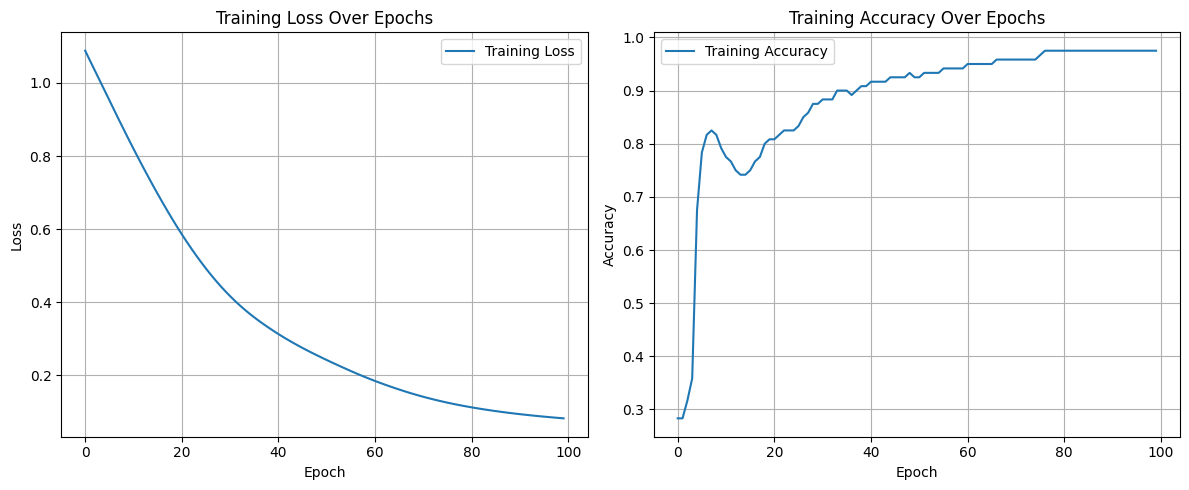

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Training Loss')
plt.title('Training Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Training Accuracy')
plt.title('Training Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# The hardcoded sample_raw corresponds to the first entry of the Iris dataset (SepalLengthCm, SepalWidthCm, PetalLengthCm, PetalWidthCm)
sample_raw = np.array([[5.1, 3.5, 1.4, 0.2]])
sample_scaled = scaler.transform(sample_raw)
sample = torch.tensor(sample_scaled, dtype=torch.float32).to(device)

# Use the currently trained model directly
model.eval() # Set the main model to evaluation mode
with torch.no_grad():
    pred = torch.argmax(model(sample), dim=1)
    predicted_class_name = iris_target_names[pred.item()] # Use iris_target_names
    print(f"Predicted class: {predicted_class_name}")

    # The actual class for this sample (first row of the dataset) is y[0]
    actual_class_index = y[0] # Use y[0] from the original dataset labels
    actual_class_name = iris_target_names[actual_class_index]
    print(f"Actual class: {actual_class_name}")

    if predicted_class_name == actual_class_name:
        print("Prediction is CORRECT!")
    else:
        print("Prediction is INCORRECT.")

Predicted class: Iris-setosa
Actual class: Iris-setosa
Prediction is CORRECT!


Accuracy on the test set: 0.9667

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


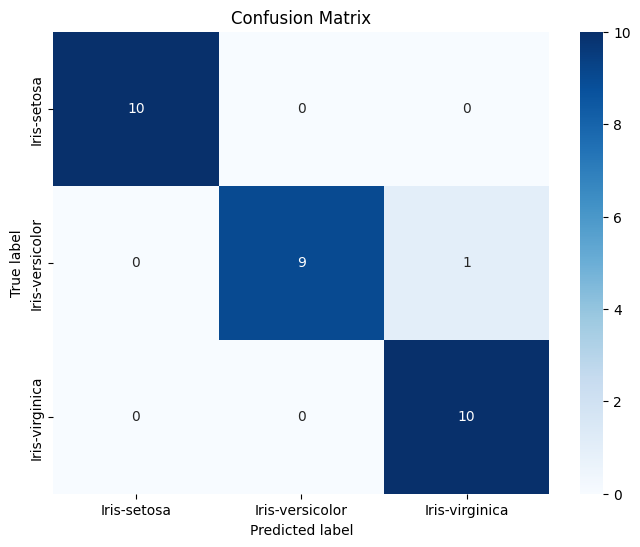


Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



In [ ]:
model.eval() # Set model to evaluation mode
with torch.no_grad():
    outputs_test = model(X_test)
    _, predicted = torch.max(outputs_test.data, 1)

# Move tensors to CPU and convert to numpy for scikit-learn metrics
y_test_np = y_test.cpu().numpy()
predicted_np = predicted.cpu().numpy()

# Calculate Accuracy Score
accuracy = accuracy_score(y_test_np, predicted_np)
print(f'Accuracy on the test set: {accuracy:.4f}')

# Calculate Confusion Matrix
cm = confusion_matrix(y_test_np, predicted_np)
print('\nConfusion Matrix:')
print(cm)

# Plot Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues',
            xticklabels=iris_target_names, yticklabels=iris_target_names) # Use iris_target_names
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix')
plt.show()

# Generate and print the classification report
from sklearn.metrics import classification_report
report = classification_report(y_test_np, predicted_np, target_names=iris_target_names) # Use iris_target_names
print('\nClassification Report:')
print(report)

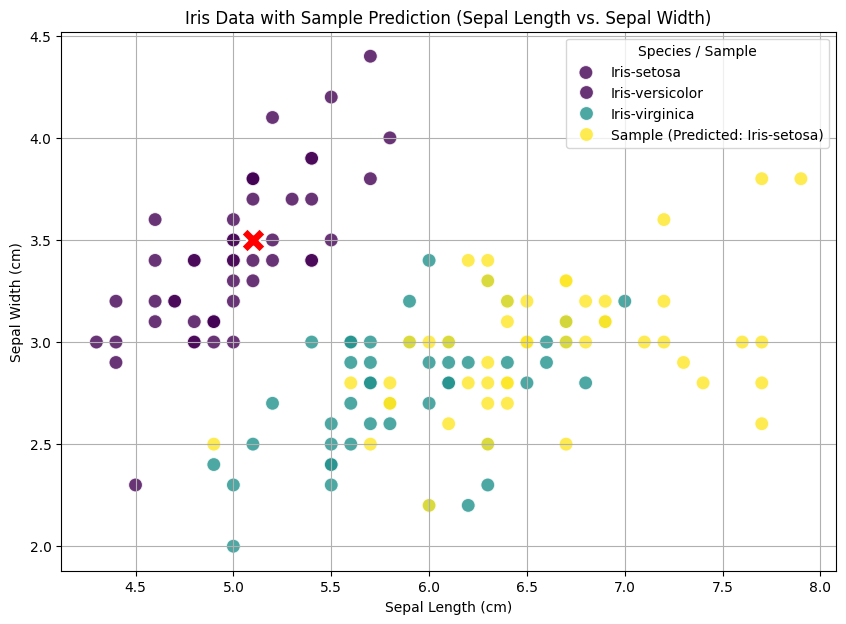

In [ ]:
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=df['SepalLengthCm'], # Use Sepal Length from df
    y=df['SepalWidthCm'], # Use Sepal Width from df
    hue=df['Species'].astype('category').cat.codes, # Color by actual species numerical codes
    palette='viridis', # Color palette
    s=100, # Size of points
    legend='full', # Show full legend
    alpha=0.8
)

# Plot the sample point
sns.scatterplot(
    x=[sample_raw[0, 0]], # Sepal length of sample
    y=[sample_raw[0, 1]], # Sepal width of sample
    marker='X', # Use an 'X' marker
    s=300, # Larger size for the sample
    color='red', # Red color for emphasis
    label='Sample (Predicted: ' + predicted_class_name + ')', # Label with predicted class
    zorder=5 # Ensure it's on top
)

plt.title('Iris Data with Sample Prediction (Sepal Length vs. Sepal Width)')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
# Update legend to show actual species names from iris_target_names
plt.legend(title='Species / Sample', labels=list(iris_target_names) + ['Sample (Predicted: ' + predicted_class_name + ')'])
plt.grid(True)
plt.show()

This plot shows the Iris data points based on sepal length and sepal width, colored by their actual species. The red 'X' marks the sample, with its predicted class displayed in the legend. We can observe how well the prediction aligns with the clusters of actual species.